In [ ]:

import numpy as np

# ex 1
def ksvd_update(Y, D, X):
    D = D.copy()
    X = X.copy()

    R = Y - D @ X

    for j in range(D.shape[1]):
        support = np.flatnonzero(X[j, :])

        if support.size == 0:
            continue

        R[:, support] += np.outer(D[:, j], X[j, support])

        U, s, Vt = np.linalg.svd(R[:, support], full_matrices=False)

        D[:, j] = U[:, 0]
        X[j, support] = s[0] * Vt[0, :]

        R[:, support] -= np.outer(D[:, j], X[j, support])

    return D, X

In [4]:
# test data for ex 1:
Y = np.array([
    [2., 4., 0.],
    [1., 2., 3.]
])

D = np.array([
    [1., 0.],
    [0., 1.]
])

X = np.array([
    [2., 4., 0.],
    [0., 0., 3.]
])

In [5]:
error_before = np.linalg.norm(Y - D @ X, "fro")

D_new, X_new = ksvd_update(Y, D, X)

error_after = np.linalg.norm(Y - D_new @ X_new, "fro")

print("Error before:", error_before)
print("Error after:", error_after)

print("\nNew dictionary:\n", D_new)
print("\nNew coefficients:\n", X_new)
print("\nReconstructed Y:\n", D_new @ X_new)

print("\nAtom norms:", np.linalg.norm(D_new, axis=0))
print("Nonzero coefficients:", np.count_nonzero(X_new, axis=0))

Error before: 2.23606797749979
Error after: 4.965068306494546e-16

New dictionary:
 [[-0.89442719  0.        ]
 [-0.4472136   1.        ]]

New coefficients:
 [[-2.23606798 -4.47213595  0.        ]
 [ 0.          0.          3.        ]]

Reconstructed Y:
 [[2. 4. 0.]
 [1. 2. 3.]]

Atom norms: [1. 1.]
Nonzero coefficients: [1 1 1]


In [8]:
# ex 2
def omp(D, y, k): # from lab 2
    n_D = D.shape[1]

    x = np.zeros(n_D)
    r = y.copy()
    selected = []

    for i in range(k):
        correlations = D.T @ r

        scores = np.abs(correlations)
        scores[selected] = -np.inf

        j = np.argmax(scores)

        if scores[j] < 1e-10:
            break

        selected.append(j)

        D_selected = D[:, selected]

        coefficients, _, _, _ = np.linalg.lstsq(
            D_selected, y, rcond=None
        )

        r = y - D_selected @ coefficients

        if np.linalg.norm(r) < 1e-10:
            break

    x[selected] = coefficients if selected else []

    return x

def dl(Y, D, tau, max_iter=10):
    k = D.shape[1]
    p = Y.shape[1]

    X = np.zeros((k, p))
    errors = []

    for iteration in range(max_iter):
        for i in range(p):
            X[:, i] = omp(D, Y[:, i], tau)

        D, X = ksvd_update(Y, D, X)

        error = np.linalg.norm(Y - D @ X, "fro")
        errors.append(error)

        print(f"Iteration {iteration + 1}: {error:.6f}")

    return D, X, errors

In [ ]:
# test for ex 2:
Y = np.array([
    [2., 4., 0.],
    [1., 2., 3.]
])

D_initial = np.array([
    [1., 0.],
    [0., 1.]
])

D, X, errors = dl(Y, D_initial, tau=1, max_iter=5)

print("\nLearned dictionary:\n", D)
print("\nLearned coefficients:\n", X)
print("\nReconstructed Y:\n", D @ X)

Iteration 1: 0.000000
Iteration 2: 0.000000
Iteration 3: 0.000000
Iteration 4: 0.000000
Iteration 5: 0.000000

Learned dictionary:
 [[-0.89442719  0.        ]
 [-0.4472136   1.        ]]

Learned coefficients:
 [[-2.23606798 -4.47213595  0.        ]
 [ 0.          0.          3.        ]]

Reconstructed Y:
 [[2. 4. 0.]
 [1. 2. 3.]]


In [ ]:
# Ex. 3
# Functions from lab 2
import struct
import tarfile

def _read_images(tar, name):
    with tar.extractfile(name) as file:
        magic, count, rows, cols = struct.unpack(">4I", file.read(16))
        if magic != 2051:
            raise ValueError(f"Unexpected image magic number in {name}: {magic}")
        pixels = np.frombuffer(file.read(), dtype=np.uint8)

    if pixels.size != count * rows * cols:
        raise ValueError(f"Image data length mismatch in {name}")

    return pixels.reshape(count, rows * cols)

def _read_labels(tar, name):
    with tar.extractfile(name) as file:
        magic, count = struct.unpack(">2I", file.read(8))
        if magic != 2049:
            raise ValueError(f"Unexpected label magic number in {name}: {magic}")
        labels = np.frombuffer(file.read(), dtype=np.uint8)

    if labels.size != count:
        raise ValueError(f"Label data length mismatch in {name}")

    return labels

def load_fashion_mnist(archive_path):
    with tarfile.open(archive_path, "r:gz") as tar:
        train_images = _read_images(tar, "train-images-idx3-ubyte")
        train_labels = _read_labels(tar, "train-labels-idx1-ubyte")
        test_images = _read_images(tar, "t10k-images-idx3-ubyte")
        test_labels = _read_labels(tar, "t10k-labels-idx1-ubyte")

    return train_images, train_labels, test_images, test_labels

In [11]:
train, train_labels, test, test_labels = load_fashion_mnist(
    "../lab2/Lab 2 material/fashion_all.tar.gz"
)
print("Training images:", train.shape)
print("Training labels:", train_labels.shape)
print("Test images:", test.shape)
print("Test labels:", test_labels.shape)

print("Pixel range:", train.min(), train.max())

Training images: (60000, 784)
Training labels: (60000,)
Test images: (10000, 784)
Test labels: (10000,)
Pixel range: 0 255


In [12]:
rng = np.random.default_rng(42)

indices = rng.choice(
    train.shape[0],
    size=6000,
    replace=False
)

Y = train[indices].T.astype(float) / 255.0
labels = train_labels[indices]

Y_test = test.T.astype(float) / 255.0

print("Y:", Y.shape)
print("Labels:", labels.shape)
print("Y_test:", Y_test.shape)

Y: (784, 6000)
Labels: (6000,)
Y_test: (784, 10000)


In [ ]:
k = 1000
tau = 5
max_iter = 5

atom_indices = rng.choice(
    Y.shape[1],
    size=k,
    replace=False
)

D_initial = Y[:, atom_indices].copy()

norms = np.linalg.norm(D_initial, axis=0)

D_initial /= norms

print("Dictionary shape:", D_initial.shape)
print("First 5 atom norms:", np.linalg.norm(D_initial, axis=0)[:5])

Dictionary shape: (784, 1000)
First 5 atom norms: [1. 1. 1. 1. 1.]


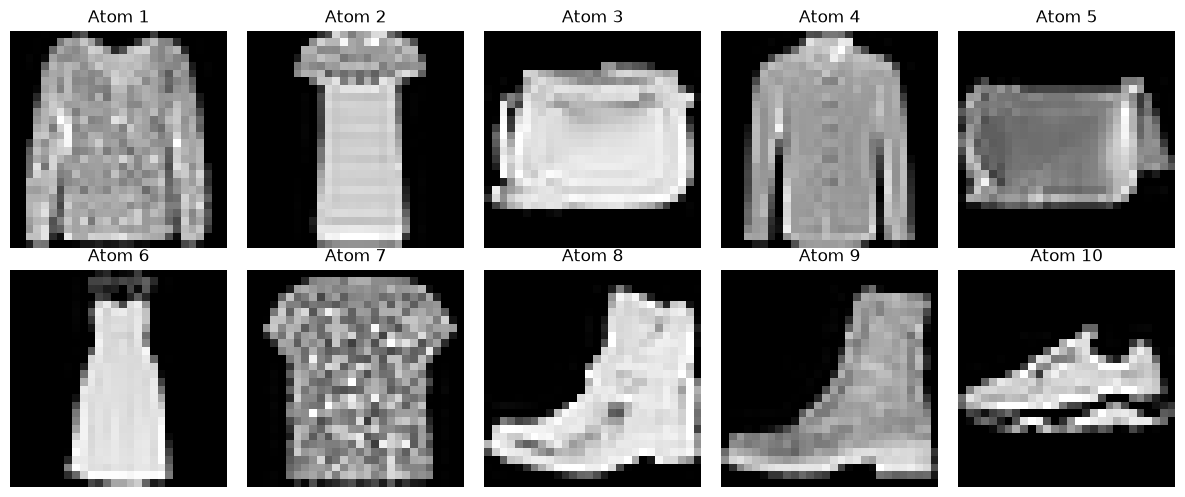

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        D_initial[:, i].reshape(28, 28),
        cmap="gray"
    )
    ax.set_title(f"Atom {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

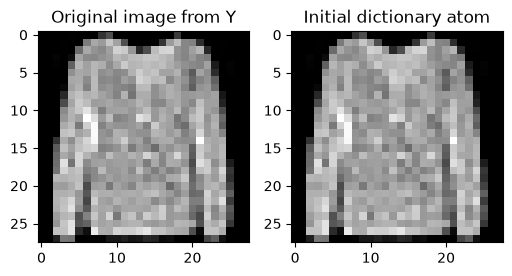

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(
    Y[:, atom_indices[0]].reshape(28, 28),
    cmap="gray"
)
axes[0].set_title("Original image from Y")

axes[1].imshow(
    D_initial[:, 0].reshape(28, 28),
    cmap="gray"
)
axes[1].set_title("Initial dictionary atom")

plt.show()

In [ ]:
# Training
D, X, errors = dl(Y, D_initial, tau, max_iter)
print("Dictionary shape:", D.shape)
print("Coefficients shape:", X.shape)

print("Dictionary normalized:", np.allclose(np.linalg.norm(D, axis=0), 1))

print("Maximum nonzero coefficients:", np.count_nonzero(X, axis=0).max())

Iteration 1: 222.492041
Iteration 2: 214.580637
Iteration 3: 211.715473
Iteration 4: 210.034560
Iteration 5: 208.733375
Dictionary shape: (784, 1000)
Coefficients shape: (1000, 6000)
Dictionary normalized: True
Maximum nonzero coefficients: 5


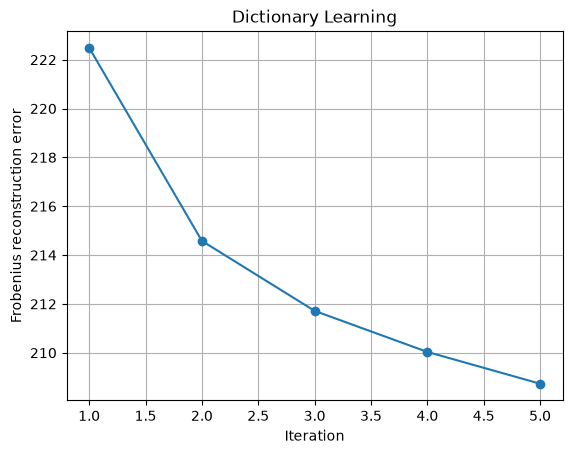

In [19]:
plt.plot(
    range(1, len(errors) + 1),
    errors,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Frobenius reconstruction error")
plt.title("Dictionary Learning")
plt.grid()
plt.show()

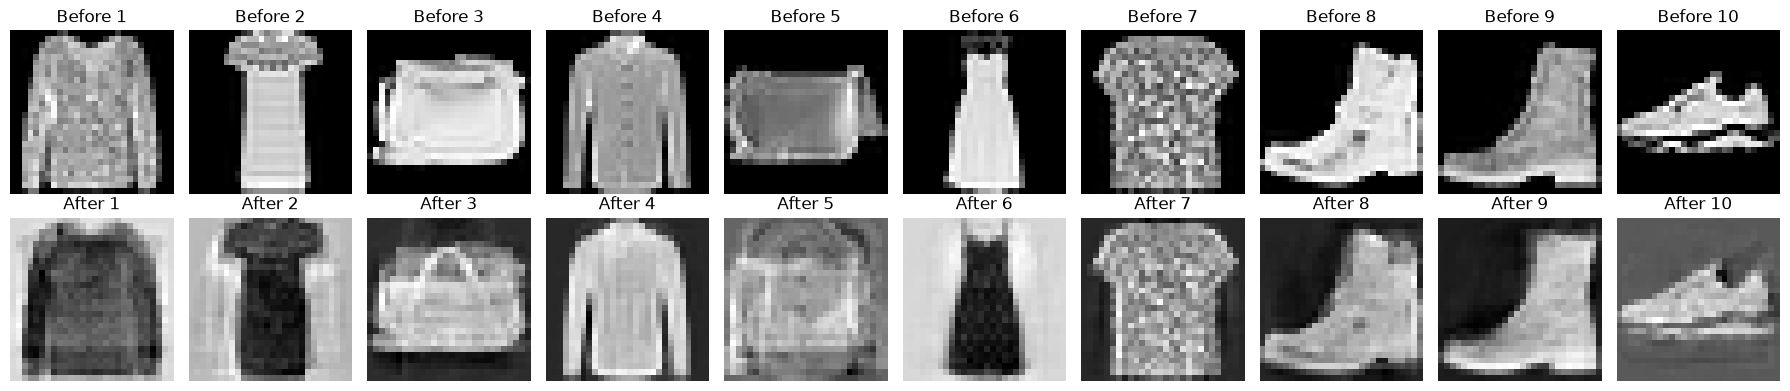

In [20]:
fig, axes = plt.subplots(2, 10, figsize=(18, 4))

for i in range(10):
    # OG dictionary atom
    axes[0, i].imshow(
        D_initial[:, i].reshape(28, 28),
        cmap="gray"
    )
    axes[0, i].set_title(f"Before {i + 1}")
    axes[0, i].axis("off")

    # Learned dictionary atom
    axes[1, i].imshow(
        D[:, i].reshape(28, 28),
        cmap="gray"
    )
    axes[1, i].set_title(f"After {i + 1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

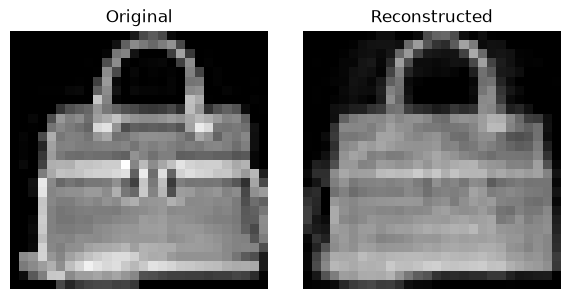

In [21]:
i = 0

y = Y[:, i]
x = X[:, i]

y_reconstructed = D @ x

fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(
    y.reshape(28, 28),
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0].set_title("Original")

axes[1].imshow(
    y_reconstructed.reshape(28, 28),
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title("Reconstructed")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
support = np.flatnonzero(x)

print("Selected atoms:", support)
print("Coefficients:", x[support])

Selected atoms: [ 67 139 159 760 863]
Coefficients: [10.6297439   1.52604304  0.81642506  1.06082288  0.97751573]


In [23]:
# Error with RMSE
Y_reconstructed = D @ X
R = Y - Y_reconstructed

rmse = np.sqrt(np.mean(R ** 2))

relative_error = (
    np.linalg.norm(R, "fro")
    / np.linalg.norm(Y, "fro")
)

print("RMSE:", rmse)
print("Relative error:", relative_error)

RMSE: 0.09624058149869208
Relative error: 0.21040219466996377


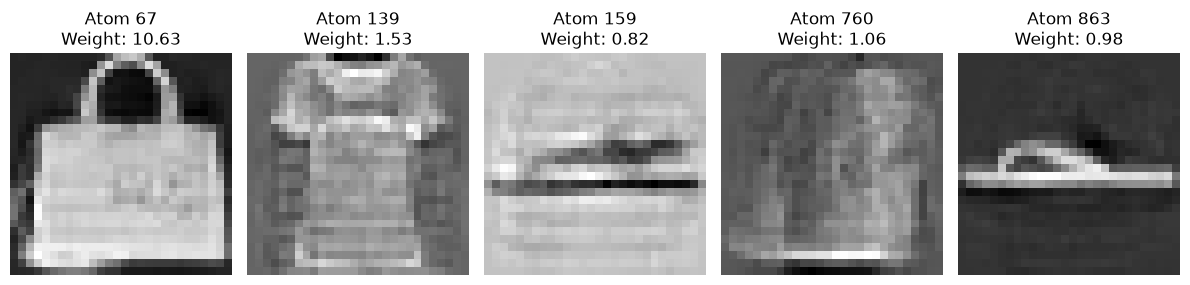

In [24]:
fig, axes = plt.subplots(1, len(support), figsize=(12, 3))

for ax, j in zip(axes, support):
    ax.imshow(
        D[:, j].reshape(28, 28),
        cmap="gray"
    )
    ax.set_title(f"Atom {j}\nWeight: {x[j]:.2f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

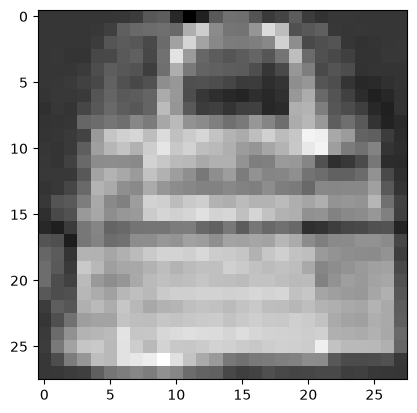

In [25]:
# Generate a new image using a custom sparse code TEST

x_custom = np.zeros(1000)

x_custom[67] = 8
x_custom[139] = 3
x_custom[159] = 2

generated_image = D @ x_custom

plt.imshow(generated_image.reshape(28, 28), cmap="gray")
plt.show()

In [27]:
# min ||H-WX||_F^2

# 0	T-shirt/top
# 1	Trouser
# 2	Pullover
# 3	Dress
# 4	Coat
# 5	Sandal
# 6	Shirt
# 7	Sneaker
# 8	Bag
# 9	Ankle boot

print(labels[:10])

H = np.eye(10)[labels].T

print("H shape:", H.shape)
print("First label:", labels[0])
print("First column of H:", H[:, 0])

[8 3 5 3 7 4 2 5 6 7]
H shape: (10, 6000)
First label: 8
First column of H: [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]


In [28]:
W = np.linalg.lstsq(X.T, H.T, rcond=None)[0].T

print("W shape:", W.shape)

W shape: (10, 1000)


In [29]:
x = X[:, 0]

scores = W @ x

prediction = np.argmax(scores)

print("Scores:", scores)
print("Predicted label:", prediction)
print("Actual label:", labels[0])

Scores: [ 0.16564705 -0.00462789 -0.00568164 -0.02442386 -0.03667558 -0.02230999
  0.04312032 -0.02764493  0.73167112 -0.0245252 ]
Predicted label: 8
Actual label: 8


In [31]:
x = X[:, 4]

print("Shape:", x.shape)
print("Selected atoms:", np.flatnonzero(x))
print("Weights:", x[np.flatnonzero(x)])

Shape: (1000,)
Selected atoms: [ 26  99 171 235 909]
Weights: [1.11900691 0.49665438 2.3595612  0.76339878 3.84567752]


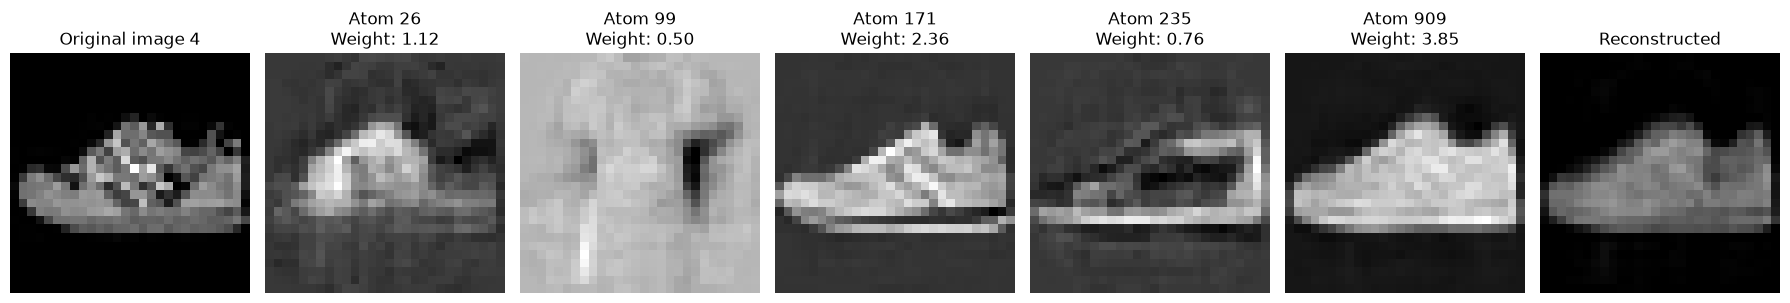

In [32]:
i = 4

y = Y[:, i]
x = X[:, i]

support = np.flatnonzero(x)

fig, axes = plt.subplots(
    1, len(support) + 2, figsize=(18, 4)
)

# Original image
axes[0].imshow(y.reshape(28, 28), cmap="gray")
axes[0].set_title(f"Original image {i}")

# Selected dictionary atoms
for ax, j in zip(axes[1:-1], support):
    ax.imshow(D[:, j].reshape(28, 28), cmap="gray")
    ax.set_title(f"Atom {j}\nWeight: {x[j]:.2f}")

# Reconstructed image
axes[-1].imshow(
    (D @ x).reshape(28, 28),
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[-1].set_title("Reconstructed")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [33]:
# Randomly select 10 test images to evaluate the model
test_indices = rng.choice(
    Y_test.shape[1],
    size=10,
    replace=False
)

print(test_indices)

[5951 1188 5691  724 5074 8182 5549 8604 4552 3570]


In [36]:
predictions = []

for i in test_indices:
    y = Y_test[:, i]

    x = omp(D, y, tau)

    scores = W @ x

    prediction = np.argmax(scores)
    predictions.append(prediction)

predictions = np.array(predictions)

actual = test_labels[test_indices]

print("Predictions:", predictions)
print("Actual:     ", actual)

accuracy = np.mean(predictions == actual) * 100

print(f"Classification accuracy: {accuracy:.1f}%")

Predictions: [0 6 8 2 9 5 7 7 4 7]
Actual:      [0 6 8 6 9 5 7 7 2 7]
Classification accuracy: 80.0%


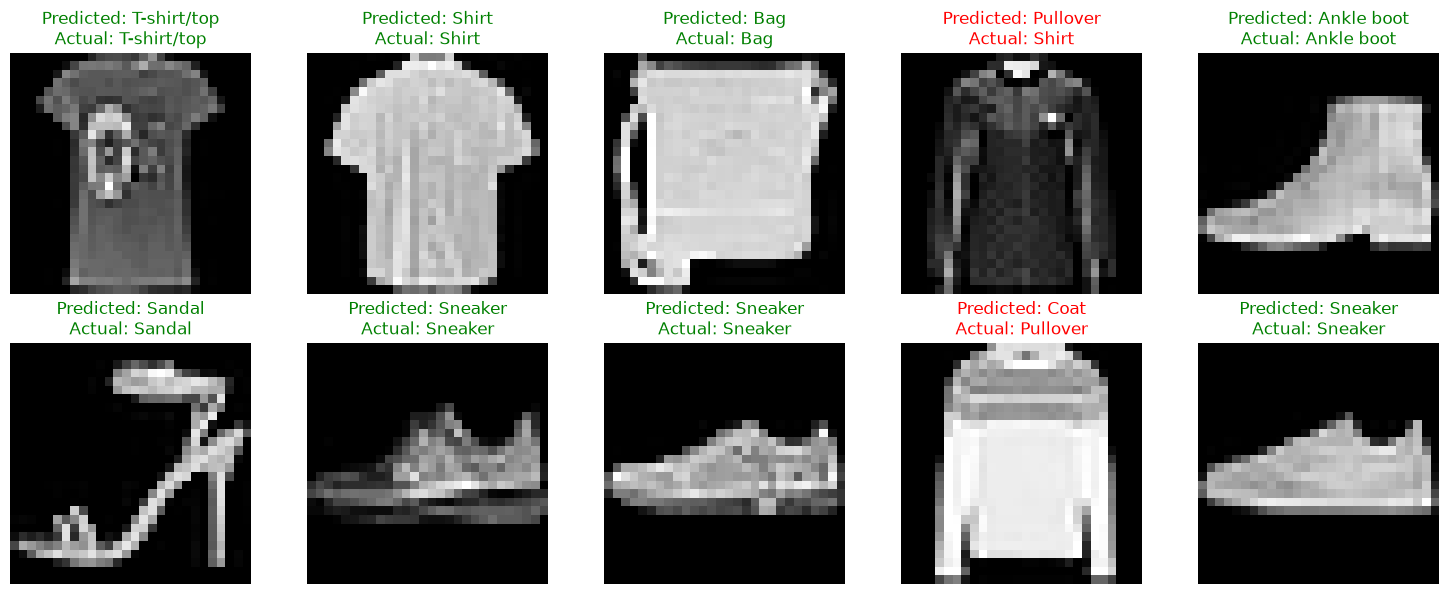

In [37]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for j, ax in enumerate(axes.flat):

    i = test_indices[j]

    ax.imshow(
        Y_test[:, i].reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    predicted_class = class_names[predictions[j]]
    actual_class = class_names[actual[j]]

    color = "green" if predictions[j] == actual[j] else "red"

    ax.set_title(
        f"Predicted: {predicted_class}\nActual: {actual_class}",
        color=color
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [38]:
D_example = np.array([
    [1., 0.6, 0.],
    [0., 0.8, 0.],
    [0., 0., 1.]
])

y_example = np.array([3., 1., 0.2])

x_example = omp(D_example, y_example, 2)

print("Coefficients:", x_example)
print("Reconstruction:", D_example @ x_example)
print("Residual:", y_example - D_example @ x_example)

Coefficients: [2.25 1.25 0.  ]
Reconstruction: [3. 1. 0.]
Residual: [4.4408921e-16 0.0000000e+00 2.0000000e-01]
